In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%matplotlib inline

In [77]:
df = pd.read_csv('height-weight.csv')

In [78]:
df.head()

,Weight,Height
0,45,120
1,58,135
2,48,123
3,60,145
4,70,160


Text(0, 0.5, 'Height')

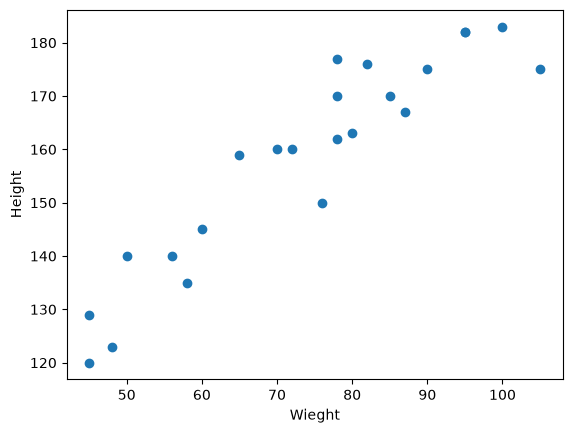

In [79]:
##scatter plot
plt.scatter(df['Weight'],df['Height'])
plt.xlabel("Wieght")
plt.ylabel("Height")

In [80]:
##Correlation
df.corr()

,Weight,Height
Weight,1.000000,0.931142
Height,0.931142,1.000000


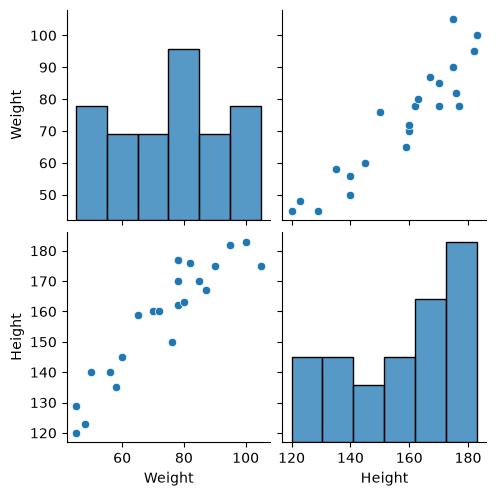

In [81]:
## Seaborn
import seaborn as sns
sns.pairplot(df)

In [82]:
## Independent and dependent features
X=df[['Weight']]   #Independent feature should always be a dataframe or 2D array
X

,Weight
0,45
1,58
2,48
3,60
4,70
5,78
6,80
7,90
8,95
9,78


In [83]:
Y = df['Height'] #Dependent can be in series or in 1D array
Y

0     120
1     135
2     123
3     145
4     160
5     162
6     163
7     175
8     182
9     170
10    176
11    182
12    175
13    183
14    170
15    177
16    140
17    159
18    150
19    167
20    129
21    140
22    160
Name: Height, dtype: int64

In [84]:
## Train Test Split
from sklearn.model_selection import train_test_split
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.25,random_state=42)

In [85]:
## Standardization
from sklearn.preprocessing import StandardScaler

In [86]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)

In [87]:
X_test = scaler.transform(X_test)

In [88]:
X_test

array([[ 0.33497168],
       [ 0.33497168],
       [-1.6641678 ],
       [ 1.36483141],
       [-0.45256812],
       [ 1.97063125]])

In [89]:
## apply Simple Linear Regression
from sklearn.linear_model import LinearRegression

In [90]:
regression = LinearRegression(n_jobs=-1)

In [91]:
regression.fit(X_train,Y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",-1
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[17.3]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,156.5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[4.12]


In [92]:
print("coefficient or slope",regression.coef_)
print("Intercept",regression.intercept_)

coefficient or slope [17.2982057]
Intercept 156.47058823529412


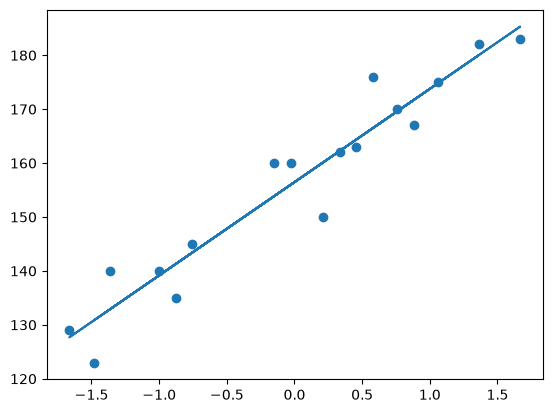

In [96]:
## plot Training data plot best line
plt.scatter(X_train,Y_train)
plt.plot(X_train,regression.predict(X_train))

# Prediction of Test Data
1. predicted height output = intercept + coef_(Weight)
2. y_pred_test = 156.470 + 17.29(X_test)

In [98]:
## Prediction for test data
y_pred = regression.predict(X_test)

In [99]:
## Performance Metrics
from sklearn.metrics import mean_absolute_error,mean_squared_error

In [101]:
mse = mean_squared_error(Y_test,y_pred)
mae = mean_absolute_error(Y_test,y_pred)
rmse = np.sqrt(mse)
print(mse)
print(mae)
print(rmse)

114.84069295228699
9.66512588679501
10.716374991212605


# R Square

## Formula

\[
R^2 = 1 - \frac{SSR}{SST}
\]

- **R²** = Coefficient of determination
- **SSR** = Sum of squares of residuals
- **SST** = Total sum of squares

In [102]:
from sklearn.metrics import r2_score

In [104]:
score = r2_score(Y_test,y_pred)
print(score)

0.7360826717981276


In [105]:
## OLS Linear Regression
import statsmodels.api as sm


In [106]:
model = sm.OLS(Y_train,X_train).fit()

In [107]:
prediction = model.predict(X_test)
print(prediction)

[  5.79440897   5.79440897 -28.78711691  23.60913442  -7.82861638
  34.08838469]


In [108]:
print(model.summary())

                                 OLS Regression Results                                
Dep. Variable:                 Height   R-squared (uncentered):                   0.012
Model:                            OLS   Adj. R-squared (uncentered):             -0.050
Method:                 Least Squares   F-statistic:                             0.1953
Date:                Tue, 13 Oct 2026   Prob (F-statistic):                       0.664
Time:                        01:53:28   Log-Likelihood:                         -110.03
No. Observations:                  17   AIC:                                      222.1
Df Residuals:                      16   BIC:                                      222.9
Df Model:                           1                                                  
Covariance Type:            nonrobust                                                  
                 coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------

In [110]:
##Prediction for new data
regression.predict(scaler.transform([[72]]))

c:\Users\chauh\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


array([155.97744705])